# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

**Dhiyaa Abdu Madkhali - 2230004228**

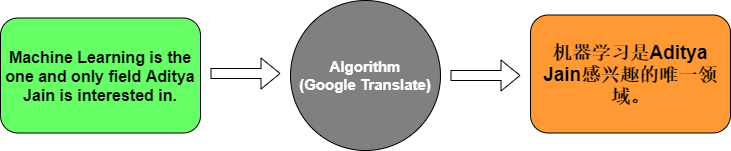

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]])

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.1429 - loss: 2.4820

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.1429 - loss: 2.4820 - val_accuracy: 0.0000e+00 - val_loss: 2.4878


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.5714 - loss: 2.4716

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step - accuracy: 0.5714 - loss: 2.4716 - val_accuracy: 0.0000e+00 - val_loss: 2.4903


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.7143 - loss: 0.5287 - val_accuracy: 0.0000e+00 - val_loss: 5.9330


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step - accuracy: 0.7143 - loss: 1.7486

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 511ms/step - accuracy: 0.7143 - loss: 1.7486


Test Accuracy: 0.7142857313156128


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 291ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 318ms/step


Input: How are you?
Translation: ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. **Embedding layer:** It changes each word index into a dense vector of numbers (64 numbers in this model). The index itself is only an ID, while the vector is learned during training, so words used in similar ways get similar vectors.

3. **Encoder LSTM:** It reads the English sentence one word at a time and updates its memory after each word. Its final hidden state is a fixed-size summary of the whole sentence. `RepeatVector` then copies this summary once for each word position of the French output.

5. **Decoder LSTM:** It receives the sentence summary at every output position and produces one hidden state per position (`return_sequences=True`). Each of these states is used to predict one French word, so the decoder builds the translation step by step.

8. **Softmax:** The final Dense layer gives a score for every word in the French vocabulary. Softmax turns these scores into probabilities that add up to 1 at each position. We can then pick the most likely word with `argmax`, and the probabilities are what the `sparse_categorical_crossentropy` loss needs during training.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

**Approach**

The Kaggle dataset has about 175,000 English-French sentence pairs. Training on all of them would take a long time on a laptop, so this solution uses short sentences (up to 6 English words and 8 French words) and keeps one French translation for each English sentence. The model has the same encoder-decoder structure as the LSTM model above, with larger layers.

In [8]:
import re
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)

df = pd.read_csv("dataset/eng_-french.csv")
df.columns = ["english", "french"]

print("Number of sentence pairs:", len(df))
df.head()

Number of sentence pairs: 175621


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [9]:
def clean_text(text):
    text = str(text).lower()
    text = text.replace("\u2019", "'").replace("\u202f", " ").replace("\xa0", " ")
    text = re.sub(r"[^a-zàâäçéèêëîïôöùûüÿœæ' ]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df["english"] = df["english"].map(clean_text)
df["french"] = df["french"].map(clean_text)

short = df[(df["english"].str.split().str.len() <= 6) & (df["french"].str.split().str.len() <= 8)]
short = short.drop_duplicates("english")
data = short.sample(n=30000, random_state=42).reset_index(drop=True)

print("Short sentence pairs:", len(short))
print("Pairs used for training and testing:", len(data))
data.head()

Short sentence pairs: 71998
Pairs used for training and testing: 30000


,english,french
0,tom brought that,tom a apporté ça
1,i know that you're clever,je sais que tu es intelligent
2,tom finished his meal first,tom a terminé son repas le premier
3,it's cooler here,il fait plus frais ici
4,our team lost the first game,notre équipe a perdu la première partie


In [10]:
tokenizer_eng = Tokenizer(filters="")
tokenizer_eng.fit_on_texts(data["english"])
tokenizer_frn = Tokenizer(filters="")
tokenizer_frn.fit_on_texts(data["french"])

eng_vocab = len(tokenizer_eng.word_index) + 1
frn_vocab = len(tokenizer_frn.word_index) + 1

eng_padded = pad_sequences(tokenizer_eng.texts_to_sequences(data["english"]), padding="post")
frn_padded = pad_sequences(tokenizer_frn.texts_to_sequences(data["french"]), padding="post")

print("English vocabulary size:", eng_vocab)
print("French vocabulary size:", frn_vocab)
print("English padded shape:", eng_padded.shape)
print("French padded shape:", frn_padded.shape)

English vocabulary size: 7405
French vocabulary size: 11190
English padded shape: (30000, 6)
French padded shape: (30000, 8)


In [11]:
eng_train, eng_test, frn_train, frn_test, text_train, text_test = train_test_split(
    eng_padded, frn_padded, data.index.values, test_size=0.1, random_state=42
)

translator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(eng_padded.shape[1],)),
    tf.keras.layers.Embedding(eng_vocab, 128, mask_zero=True),
    tf.keras.layers.LSTM(256),                                   # encoder
    tf.keras.layers.RepeatVector(frn_padded.shape[1]),
    tf.keras.layers.LSTM(256, return_sequences=True),            # decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax")),
])

translator.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
translator.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 6, 128)         │       947,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 8, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 8, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 8, 11190)       │     2,875,830 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,743,222 (18.09 MB)

 Trainable params: 4,743,222 (18.09 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = translator.fit(
    eng_train,
    np.expand_dims(frn_train, -1),
    epochs=30,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=2,
)

Epoch 1/30


380/380 - 24s - 64ms/step - accuracy: 0.3577 - loss: 5.1088 - val_accuracy: 0.3756 - val_loss: 4.6785


Epoch 2/30


380/380 - 21s - 55ms/step - accuracy: 0.3791 - loss: 4.5290 - val_accuracy: 0.3862 - val_loss: 4.5324


Epoch 3/30


380/380 - 22s - 57ms/step - accuracy: 0.3889 - loss: 4.4118 - val_accuracy: 0.3905 - val_loss: 4.4784


... (50 outputs left out)

Epoch 29/30


380/380 - 20s - 53ms/step - accuracy: 0.7188 - loss: 1.2798 - val_accuracy: 0.5453 - val_loss: 3.1868


Epoch 30/30


380/380 - 21s - 55ms/step - accuracy: 0.7329 - loss: 1.2061 - val_accuracy: 0.5458 - val_loss: 3.2089


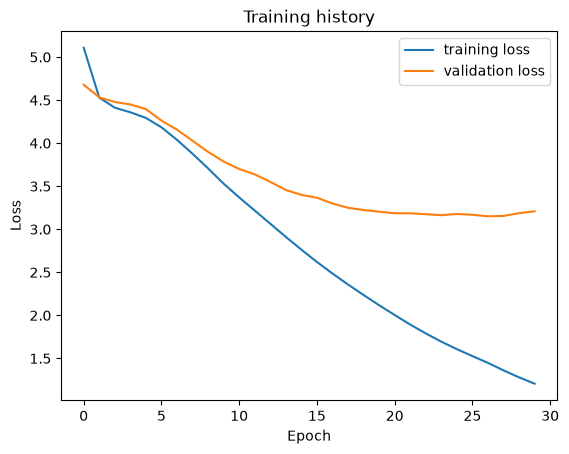

Test loss: 3.1062
Test accuracy (per word position, padding included): 0.5440


In [13]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training history")
plt.legend()
plt.show()

loss, accuracy = translator.evaluate(eng_test, np.expand_dims(frn_test, -1), verbose=0)
print(f"Test loss: {loss:.4f}")
print(f"Test accuracy (per word position, padding included): {accuracy:.4f}")

In [14]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

def translate(sentences):
    sequences = tokenizer_eng.texts_to_sequences([clean_text(s) for s in sentences])
    padded = pad_sequences(sequences, maxlen=eng_padded.shape[1], padding="post")
    predicted_ids = np.argmax(translator.predict(padded, verbose=0), axis=-1)
    return tokenizer_frn.sequences_to_texts(predicted_ids)

test_english = data.loc[text_test, "english"].tolist()
test_french = data.loc[text_test, "french"].tolist()
predictions = translate(test_english)

bleu = corpus_bleu(
    [[ref.split()] for ref in test_french],
    [pred.split() for pred in predictions],
    smoothing_function=SmoothingFunction().method1,
)
print(f"BLEU score on the test set: {bleu:.4f}\n")

for eng, ref, pred in list(zip(test_english, test_french, predictions))[:10]:
    print(f"English:    {eng}")
    print(f"Reference:  {ref}")
    print(f"Prediction: {pred}\n")

BLEU score on the test set: 0.1105

English:    there's one condition
Reference:  il y a une condition
Prediction: il y a des condition

English:    tom's plan is perfect
Reference:  le plan de tom est parfait
Prediction: le est est est est

English:    your mother is in critical condition
Reference:  ta mère se trouve dans un état critique
Prediction: ton chambre est est très en

English:    i had better ask her
Reference:  je ferais mieux de lui demander
Prediction: je me ai de de

English:    i guess we're finished
Reference:  je suppose que nous en avons terminé
Prediction: j'ai que que tu dit dit

English:    he's not all there
Reference:  il n'est pas tout à fait là
Prediction: il n'est pas pas là

English:    my father has a red beard
Reference:  mon père a une barbe rousse
Prediction: mon père est une belle

English:    don't ask for money
Reference:  ne demande pas d'argent
Prediction: ne pas pas à

English:    i'm a little thirsty myself
Reference:  j'ai moi même un petit peu

**Translating e-commerce content**

In [15]:
shop_sentences = [
    "This product is very good.",
    "I love this phone.",
    "The price is too high.",
    "This dress is beautiful.",
    "Where is my order?",
    "I want to buy this book.",
    "The shoes are too small.",
    "I am very happy with it.",
]

for sentence, french in zip(shop_sentences, translate(shop_sentences)):
    unknown = [w for w in clean_text(sentence).split() if w not in tokenizer_eng.word_index]
    note = f"  (unknown words: {unknown})" if unknown else ""
    print(f"{sentence:30} -> {french}{note}")

This product is very good.     -> ce n'est vraiment très très
I love this phone.             -> j'adore ce
The price is too high.         -> le conclusion est très
This dress is beautiful.       -> cette idée est redoutable
Where is my order?             -> où est mon
I want to buy this book.       -> je veux faire faire livre livre
The shoes are too small.       -> les chaussures sont très
I am very happy with it.       -> je suis très fatigué pour


**Results**

The model learned the basic structure of French sentences. Short, common phrases come out correct or close: *il y a des condition* for "there's one condition", *il n'est pas pas là* for "he's not all there", and *où est mon...* for "Where is my order?". Longer sentences are weaker: the model often repeats a word (*est est est*), drops the end of the sentence, or picks a common word instead of a rare one (*fatigué* instead of *content*). The BLEU score on the test set is about 0.11.

The reason is the model design. The encoder squeezes the whole English sentence into one fixed-size vector, and the decoder never sees the French words it has already produced, so it loses track of long sentences. For the e-commerce company, a model with attention (or a pretrained Transformer translation model such as MarianMT) trained on the full dataset would be needed to translate product listings and reviews reliably. This LSTM model is a working first version that shows the pipeline: cleaning the data, tokenizing, padding, training, evaluating and translating new text.